# Tập 2 · Tự dạy AI một việc thì bắt đầu từ đâu?
[![Mở trong Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ngocnguyen88/AI-from-Zero/blob/main/tap02/tap02.ipynb)

Notebook đi đủ 5 bước: **Dữ liệu → Mô hình → Huấn luyện → Đo → Dùng**, rồi làm lại lần B chỉ đổi dữ liệu.

Chạy được trên CPU, không cần GPU (Colab miễn phí hoặc máy của bạn), cả notebook vài phút.
Trên Colab: bấm **Runtime > Run all** (Chạy tất cả), hoặc chạy từng ô bằng Shift + Enter.

Thẻ trong ảnh là THẺ MẪU tự vẽ (thông tin bịa, có chữ MẪU), không phải giấy tờ thật. Ảnh nền là ảnh chụp bàn trên Wikimedia Commons. Nguồn và giấy phép: `tap02/DU-LIEU.md`, `tap03/DU-LIEU.md`.

**Ô chuẩn bị. Lấy ảnh của tập 2 và ảnh mới** (chạy 1 lần, khoảng 20 MB)

In [1]:
import os, urllib.request, zipfile               # tải bộ ảnh nếu máy chưa có
goc = 'https://raw.githubusercontent.com/ngocnguyen88/AI-from-Zero/main/'
def tai(duong, ten_zip):
    for lan in range(3):                         # mạng chập chờn thì thử lại, tối đa 3 lần
        try:
            urllib.request.urlretrieve(goc + duong, ten_zip + '.tam')
            os.replace(ten_zip + '.tam', ten_zip)
            break
        except Exception as loi:
            print('Tải lỗi, thử lại:', loi)
    zipfile.ZipFile(ten_zip).extractall('.')
if not os.path.isdir('du-lieu/100-anh'):
    tai('tap02/du-lieu.zip', 'du-lieu-tap02.zip')   # 100 ảnh + 12 ảnh khó của tập 2
if not os.path.isfile('du-lieu/nhan.csv'):
    tai('tap03/du-lieu.zip', 'du-lieu-tap03.zip')   # ảnh mới chụp + file nhãn
print(len(os.listdir('du-lieu/anh-moi')), 'ảnh mới,', len(os.listdir('du-lieu/anh-kho')), 'ảnh khó của tập 2')

420 ảnh mới, 12 ảnh khó của tập 2


**Ô 1. Đọc 100 ảnh và giấu 20 tấm làm đề thi.**
Ba thư mục = ba nhãn (đáp án). Mô hình học bằng 80 tấm, không bao giờ được thấy 20 tấm đề thi.

In [2]:
import torch
nhan_list = ['khong-phai-the', 'mat-sau', 'mat-truoc']   # ba nhãn = ba thư mục
anh = []                                                 # mỗi phần tử: (đường dẫn, nhãn)
for nhan in nhan_list:
    for ten in sorted(os.listdir(f'du-lieu/100-anh/{nhan}')):
        anh.append((f'du-lieu/100-anh/{nhan}/{ten}', nhan))
for nhan in nhan_list:
    print(nhan, sum(a[1] == nhan for a in anh), 'ảnh')

torch.manual_seed(0)                                     # cùng đề thi mọi lần chạy
hoc, thi = torch.utils.data.random_split(list(range(100)), [80, 20])
hoc, thi = list(hoc), list(thi)
print('học', len(hoc), '| đề thi', len(thi))

khong-phai-the 34 ảnh
mat-sau 33 ảnh
mat-truoc 33 ảnh
học 80 | đề thi 20


**Ô 2. Mượn mô hình có sẵn, khoá phần biết nhìn, lắp phần trả lời mới.**
Phần biết nhìn bị khoá, không đổi khi học, nên mỗi ảnh chỉ cần cho nó nhìn một lần.

In [3]:
import time
from torch import nn
from torchvision import models
from PIL import Image
w = models.ResNet18_Weights.IMAGENET1K_V1
mat = models.resnet18(weights=w)
mat.fc = nn.Identity()  # khoá phần biết nhìn
mat.eval()
lop_cuoi = nn.Linear(512, 3)  # phần trả lời mới: 3 nhãn

def nhin(cac_duong_dan):                              # cho phần biết nhìn xem ảnh
    with torch.no_grad():
        return torch.cat([mat(torch.stack([w.transforms()(Image.open(p).convert('RGB')) for p in cac_duong_dan[i:i + 32]]))
                          for i in range(0, len(cac_duong_dan), 32)])

t0 = time.time()
X = nhin([a[0] for a in anh])                         # 100 ảnh, mỗi ảnh nhìn đúng một lần
y = torch.tensor([nhan_list.index(a[1]) for a in anh])
print('nhìn 100 ảnh:', f'{time.time() - t0:.1f} giây')

nhìn 100 ảnh: 4.5 giây


**Ô 3. Hàm dạy (đoán, đo lệch, chỉnh, lặp lại) và hàm chấm điểm**

In [4]:
def day(hoc, so_vong=30, hat=0):
    torch.manual_seed(hat)
    lop_cuoi = nn.Linear(512, 3)
    toi_uu = torch.optim.Adam(lop_cuoi.parameters(), lr=0.001)
    for vong in range(so_vong):
        thu_tu = torch.tensor(hoc)[torch.randperm(len(hoc))]
        for i in range(0, len(hoc), 16):               # nhóm 16 ảnh
            lo = thu_tu[i:i + 16]
            loss = nn.functional.cross_entropy(lop_cuoi(X[lo]), y[lo])   # 1. đoán
            toi_uu.zero_grad(); loss.backward()                          # 2. đo lệch
            toi_uu.step()                                                # 3. chỉnh
    return lop_cuoi

def cham(lop_cuoi, cac_anh):                           # số ảnh đoán đúng
    with torch.no_grad():
        return int((lop_cuoi(X[cac_anh]).argmax(1) == y[cac_anh]).sum())

**Ô 4. Chấm đề thi: trước khi dạy và sau khi dạy**

In [5]:
lop_0 = day(hoc, 0)                                    # chưa dạy vòng nào
print('Trước khi dạy:', cham(lop_0, thi), '/ 20')
lop_A = day(hoc)                                       # lần A: 80 ảnh, 30 vòng
print('Lần A:', cham(lop_A, thi), '/ 20')

Trước khi dạy: 1 / 20
Lần A: 20 / 20


**Ô 5. Thử ảnh thật: hai tấm thẻ nhỏ nằm trên bàn**

In [6]:
def doan(duong_dan, lop=lop_A):
    with torch.no_grad():
        p = lop(nhin([duong_dan])).softmax(1)[0]
    print(f'-> {nhan_list[p.argmax()]}  {p.max().item() * 100:.1f}%')

doan('du-lieu/anh-kho/sau-nho-tren-ban.jpg')
doan('du-lieu/anh-kho/truoc-nho-tren-ban.jpg')

-> khong-phai-the  94.2%
-> khong-phai-the  88.5%


**Ô 6. Ảnh mới: đúng kiểu còn thiếu.** Hàng trên: 6 ảnh thẻ lúc nãy. Hàng dưới: 6 ảnh mới.

['file,nhan,nhom', 'anh-moi/lan-01-1.jpg,mat-truoc,lan-01', 'anh-moi/lan-01-2.jpg,mat-truoc,lan-01', 'anh-moi/lan-01-3.jpg,mat-truoc,lan-01']
420 ảnh mới


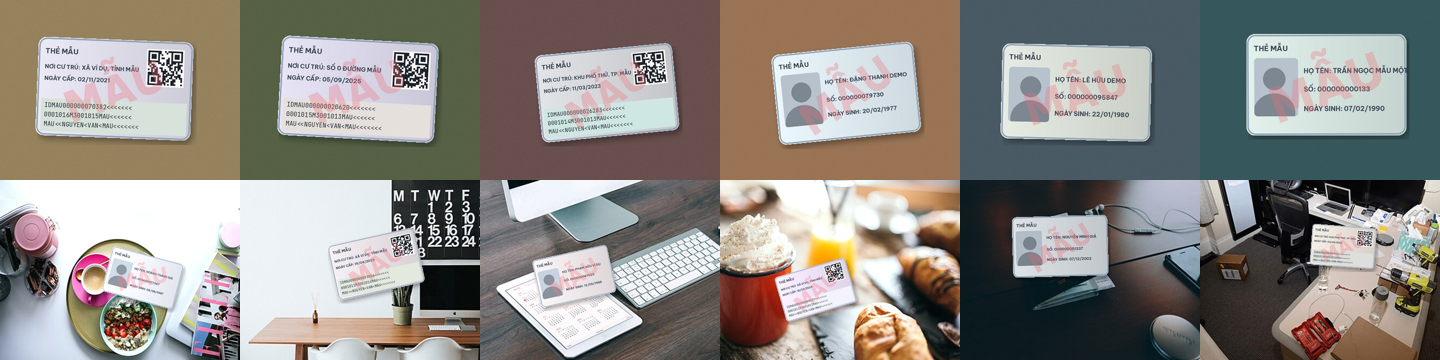

In [7]:
import csv
moi_anh = [(('du-lieu/' + d['file']), d['nhan']) for d in csv.DictReader(open('du-lieu/nhan.csv', encoding='utf-8'))]
print(open('du-lieu/nhan.csv', encoding='utf-8').read().splitlines()[:4])
print(len(moi_anh), 'ảnh mới')

def luoi(cac_duong_dan, cot=6, rong=240, cao=180):     # ghép ảnh thành lưới để xem
    g = Image.new('RGB', (cot * rong, (len(cac_duong_dan) + cot - 1) // cot * cao), 'white')
    for k, p in enumerate(cac_duong_dan):
        g.paste(Image.open(p).convert('RGB').resize((rong, cao)), (k % cot * rong, k // cot * cao))
    return g

the_tap2 = [a[0] for a in anh if a[1] != 'khong-phai-the']
the_moi = [a[0] for a in moi_anh if a[1] != 'khong-phai-the' and a[0].endswith('-1.jpg')]
luoi(the_tap2[::11][:6] + the_moi[::9][:6])

**Ô 7. Lần B: dạy lại y hệt, chỉ thêm ảnh mới vào ảnh học.**
Cùng hàm `day`, cùng số vòng. Hai cái bàn trong 2 tấm thẻ nhỏ không có trong ảnh mới, nên đây vẫn là phép thử thật.

In [8]:
t0 = time.time()
X = torch.cat([X, nhin([a[0] for a in moi_anh])])      # nhìn 420 ảnh mới, nối vào X
y = torch.cat([y, torch.tensor([nhan_list.index(a[1]) for a in moi_anh])])
moi = list(range(100, len(X)))
print('nhìn', len(moi), 'ảnh mới:', f'{time.time() - t0:.1f} giây')

lop_B = day(hoc + moi)                                 # chỉ khác: thêm ảnh mới
print('Lần B, đề thi:', cham(lop_B, thi), '/ 20')
hai_the = {'truoc-nho-tren-ban.jpg': 'mat-truoc', 'sau-nho-tren-ban.jpg': 'mat-sau'}
for ten, dung in hai_the.items():
    with torch.no_grad():
        p = lop_B(nhin(['du-lieu/anh-kho/' + ten])).softmax(1)[0]
    print(f'{ten:24s} -> {nhan_list[p.argmax()]:15s} {p.max().item() * 100:5.1f}%   (đúng là {dung})')

nhìn 420 ảnh mới: 23.9 giây


Lần B, đề thi: 19 / 20
truoc-nho-tren-ban.jpg   -> mat-sau          79.9%   (đúng là mat-truoc)
sau-nho-tren-ban.jpg     -> mat-truoc        81.5%   (đúng là mat-sau)


**Bài tự làm (khoảng 10 phút).**
1. Chạy lại notebook, và cạnh mỗi ô, ghi xem nó thuộc bước nào trong năm bước.
2. Với bài toán của bạn, viết ra năm kiểu ảnh bạn sẽ gặp ngoài đời, rồi đánh dấu kiểu nào bộ ảnh của bạn đã có. Để danh sách đó ở phần bình luận.

---
## Thêm cho ai tò mò
Không có trong video. Chạy sau khi đã chạy hết các ô trên.

**Cả 12 ảnh khó của tập 2**, lần A (80 ảnh) và lần B (80 + 420 ảnh mới). Không ảnh nào trong 12 tấm này nằm trong ảnh học.

In [9]:
kho = sorted(os.listdir('du-lieu/anh-kho'))
print(f'{"ảnh":26s} {"lần A":24s} lần B')
for t in kho:
    ra = []
    for lop in (lop_A, lop_B):
        with torch.no_grad():
            p = lop(nhin(['du-lieu/anh-kho/' + t])).softmax(1)[0]
        ra.append(f'{nhan_list[p.argmax()]} {p.max().item() * 100:.1f}%')
    print(f'{t:26s} {ra[0]:24s} {ra[1]}')

ảnh                        lần A                    lần B


phong-bi-1.jpg             khong-phai-the 89.2%     mat-sau 50.8%


phong-bi-2.jpg             khong-phai-the 99.5%     khong-phai-the 98.5%


phong-bi-3.jpg             khong-phai-the 97.8%     khong-phai-the 99.4%
sau-lon-nguoc.jpg          mat-sau 97.6%            mat-sau 97.1%


sau-nho-tren-ban.jpg       khong-phai-the 94.2%     mat-truoc 81.5%


sau-toi.jpg                mat-sau 74.2%            mat-sau 78.7%
the-mau-tap1.png           mat-truoc 70.2%          khong-phai-the 59.3%


truoc-bi-che.jpg           mat-truoc 97.1%          mat-truoc 99.5%


truoc-nghieng-35.jpg       mat-truoc 97.4%          mat-truoc 81.3%
truoc-nho-tren-ban.jpg     khong-phai-the 88.5%     mat-sau 79.9%


truoc-toi.jpg              mat-truoc 95.8%          mat-truoc 97.3%


truoc-xoay-90.jpg          mat-truoc 95.3%          mat-truoc 90.2%
